In [1]:
print("Hello, Nimish!")
print("My Python Data Analytics journey begins!")
print("Project 4: Customer Behaviour Analysis")

Hello, Nimish!
My Python Data Analytics journey begins!
Project 4: Customer Behaviour Analysis


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All data analytics libraries imported successfully!")

Matplotlib is building the font cache; this may take a moment.


All data analytics libraries imported successfully!


In [3]:
import os

folders = [
    "Data/Raw",
    "Data/Processed",
    "Images",
    "Reports"
]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

print("Project folders created successfully!")

Project folders created successfully!


In [4]:
import os

files = os.listdir("Data/Raw")

print("Files available in Raw folder:")
for file in files:
    print(file)

Files available in Raw folder:
shopping_trends_updated.csv


In [5]:
df = pd.read_csv("Data/Raw/shopping_trends_updated.csv")

print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

df.head()

Dataset loaded successfully!
Number of rows and columns: (3900, 18)


,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Payment Method,Frequency of Purchases
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Express,Yes,Yes,14,Venmo,Fortnightly
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Express,Yes,Yes,2,Cash,Fortnightly
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Free Shipping,Yes,Yes,23,Credit Card,Weekly
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,Next Day Air,Yes,Yes,49,PayPal,Weekly
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Free Shipping,Yes,Yes,31,PayPal,Annually


In [6]:
print("Dataset Information:")
df.info()

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 3900 entries, 0 to 3899
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Customer ID             3900 non-null   int64  
 1   Age                     3900 non-null   int64  
 2   Gender                  3900 non-null   str    
 3   Item Purchased          3900 non-null   str    
 4   Category                3900 non-null   str    
 5   Purchase Amount (USD)   3900 non-null   int64  
 6   Location                3900 non-null   str    
 7   Size                    3900 non-null   str    
 8   Color                   3900 non-null   str    
 9   Season                  3900 non-null   str    
 10  Review Rating           3900 non-null   float64
 11  Subscription Status     3900 non-null   str    
 12  Shipping Type           3900 non-null   str    
 13  Discount Applied        3900 non-null   str    
 14  Promo Code Used         3900 n

In [7]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal duplicate rows:")
print(df.duplicated().sum())

print("\nDataset statistical summary:")
df.describe()

Missing values in each column:
Customer ID               0
Age                       0
Gender                    0
Item Purchased            0
Category                  0
Purchase Amount (USD)     0
Location                  0
Size                      0
Color                     0
Season                    0
Review Rating             0
Subscription Status       0
Shipping Type             0
Discount Applied          0
Promo Code Used           0
Previous Purchases        0
Payment Method            0
Frequency of Purchases    0
dtype: int64

Total duplicate rows:
0

Dataset statistical summary:


,Customer ID,Age,Purchase Amount (USD),Review Rating,Previous Purchases
count,3900.000000,3900.000000,3900.000000,3900.000000,3900.000000
mean,1950.500000,44.068462,59.764359,3.749949,25.351538
std,1125.977353,15.207589,23.685392,0.716223,14.447125
min,1.000000,18.000000,20.000000,2.500000,1.000000
25%,975.750000,31.000000,39.000000,3.100000,13.000000
50%,1950.500000,44.000000,60.000000,3.700000,25.000000
75%,2925.250000,57.000000,81.000000,4.400000,38.000000
max,3900.000000,70.000000,100.000000,5.000000,50.000000


In [8]:
df_clean = df.copy()

df_clean.columns = (
    df_clean.columns
    .str.strip()
    .str.lower()
    .str.replace(r"[^\w]+", "_", regex=True)
    .str.strip("_")
)

print("Cleaned column names:")
print(df_clean.columns.tolist())

Cleaned column names:
['customer_id', 'age', 'gender', 'item_purchased', 'category', 'purchase_amount_usd', 'location', 'size', 'color', 'season', 'review_rating', 'subscription_status', 'shipping_type', 'discount_applied', 'promo_code_used', 'previous_purchases', 'payment_method', 'frequency_of_purchases']


In [9]:
print("Customer Gender:")
print(df_clean["gender"].value_counts())

print("\nProduct Categories:")
print(df_clean["category"].value_counts())

print("\nShopping Seasons:")
print(df_clean["season"].value_counts())

print("\nSubscription Status:")
print(df_clean["subscription_status"].value_counts())

print("\nPayment Methods:")
print(df_clean["payment_method"].value_counts())

Customer Gender:
gender
Male      2652
Female    1248
Name: count, dtype: int64

Product Categories:
category
Clothing       1737
Accessories    1240
Footwear        599
Outerwear       324
Name: count, dtype: int64

Shopping Seasons:
season
Spring    999
Fall      975
Winter    971
Summer    955
Name: count, dtype: int64

Subscription Status:
subscription_status
No     2847
Yes    1053
Name: count, dtype: int64

Payment Methods:
payment_method
PayPal           677
Credit Card      671
Cash             670
Debit Card       636
Venmo            634
Bank Transfer    612
Name: count, dtype: int64


In [10]:
category_analysis = (
    df_clean.groupby("category")
    .agg(
        total_purchases=("customer_id", "count"),
        total_revenue=("purchase_amount_usd", "sum"),
        average_purchase=("purchase_amount_usd", "mean")
    )
    .sort_values(by="total_revenue", ascending=False)
)

print("Sales Performance by Category:")
display(category_analysis.round(2))

Sales Performance by Category:


,total_purchases,total_revenue,average_purchase
category,,,
Clothing,1737,104264,60.03
Accessories,1240,74200,59.84
Footwear,599,36093,60.26
Outerwear,324,18524,57.17


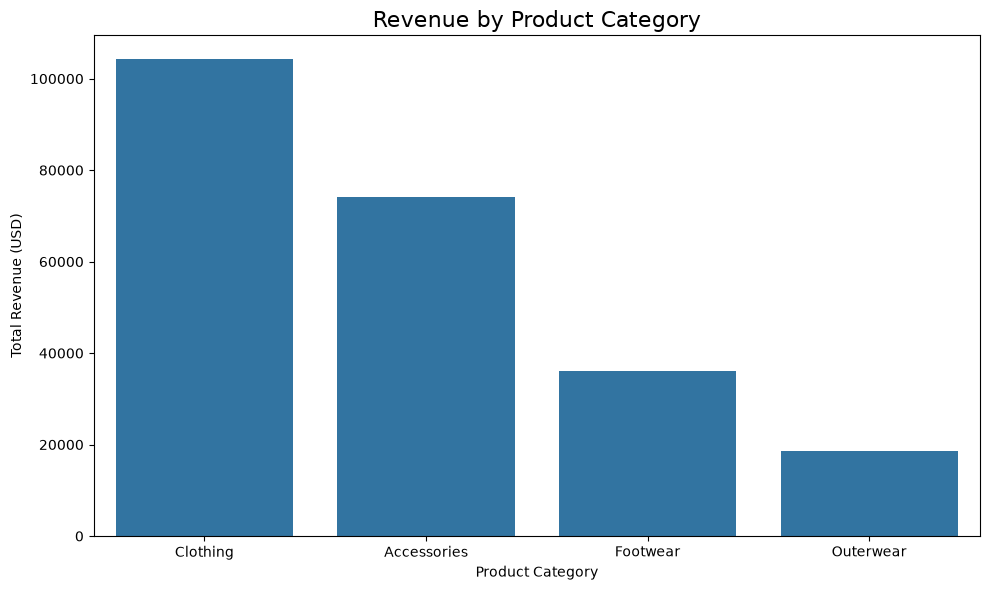

In [11]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=category_analysis.reset_index(),
    x="category",
    y="total_revenue"
)

plt.title("Revenue by Product Category", fontsize=16)
plt.xlabel("Product Category")
plt.ylabel("Total Revenue (USD)")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [12]:
df_clean["age_group"] = pd.cut(
    df_clean["age"],
    bins=[17, 25, 35, 45, 55, 65, 70],
    labels=["18-25", "26-35", "36-45", "46-55", "56-65", "66-70"]
)

age_analysis = (
    df_clean.groupby("age_group", observed=True)
    .agg(
        customer_records=("customer_id", "count"),
        total_revenue=("purchase_amount_usd", "sum"),
        average_spending=("purchase_amount_usd", "mean")
    )
)

print("Customer Spending Analysis by Age Group:")
display(age_analysis.round(2))

Customer Spending Analysis by Age Group:


,customer_records,total_revenue,average_spending
age_group,,,
18-25,571,34630,60.65
26-35,742,44342,59.76
36-45,729,43234,59.31
46-55,753,45619,60.58
56-65,750,44352,59.14
66-70,355,20904,58.88


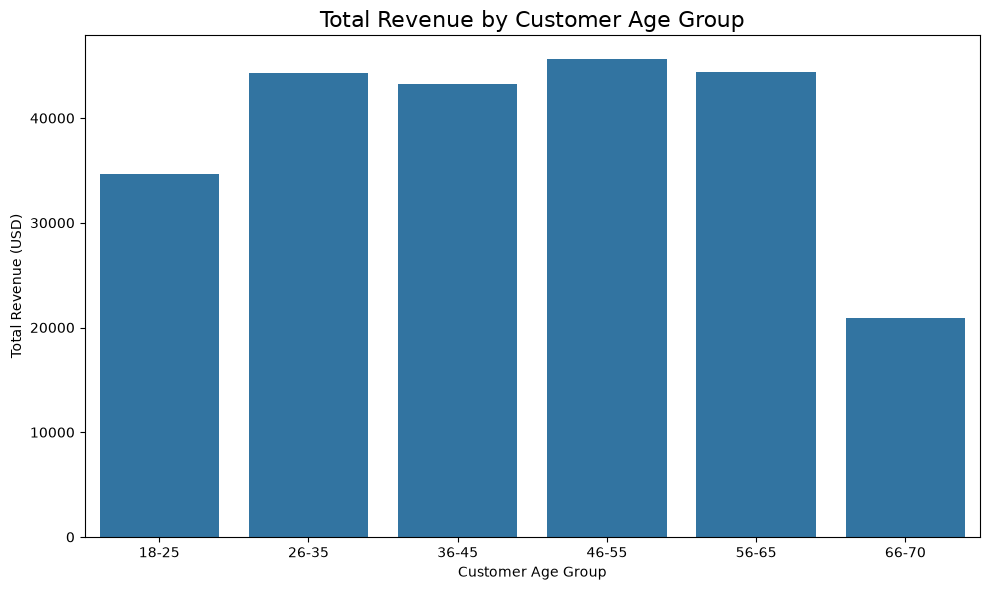

In [13]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=age_analysis.reset_index(),
    x="age_group",
    y="total_revenue"
)

plt.title("Total Revenue by Customer Age Group", fontsize=16)
plt.xlabel("Customer Age Group")
plt.ylabel("Total Revenue (USD)")

plt.tight_layout()
plt.show()

In [14]:
subscription_analysis = (
    df_clean.groupby("subscription_status")
    .agg(
        customer_records=("customer_id", "count"),
        total_revenue=("purchase_amount_usd", "sum"),
        average_spending=("purchase_amount_usd", "mean"),
        average_previous_purchases=("previous_purchases", "mean")
    )
)

print("Customer Subscription Analysis:")
display(subscription_analysis.round(2))

Customer Subscription Analysis:


,customer_records,total_revenue,average_spending,average_previous_purchases
subscription_status,,,,
No,2847,170436,59.87,25.08
Yes,1053,62645,59.49,26.08


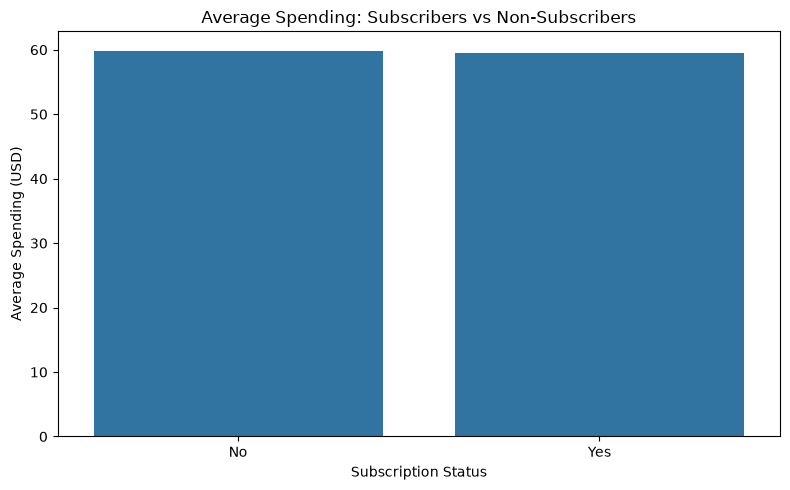

In [15]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=subscription_analysis.reset_index(),
    x="subscription_status",
    y="average_spending"
)

plt.title("Average Spending: Subscribers vs Non-Subscribers")
plt.xlabel("Subscription Status")
plt.ylabel("Average Spending (USD)")

plt.tight_layout()
plt.show()

In [16]:
discount_analysis = (
    df_clean.groupby("discount_applied")
    .agg(
        customer_records=("customer_id", "count"),
        total_revenue=("purchase_amount_usd", "sum"),
        average_spending=("purchase_amount_usd", "mean")
    )
)

promo_analysis = (
    df_clean.groupby("promo_code_used")
    .agg(
        customer_records=("customer_id", "count"),
        total_revenue=("purchase_amount_usd", "sum"),
        average_spending=("purchase_amount_usd", "mean")
    )
)

print("Discount Usage Analysis:")
display(discount_analysis.round(2))

print("\nPromotional Code Usage Analysis:")
display(promo_analysis.round(2))

Discount Usage Analysis:


,customer_records,total_revenue,average_spending
discount_applied,,,
No,2223,133670,60.13
Yes,1677,99411,59.28



Promotional Code Usage Analysis:


,customer_records,total_revenue,average_spending
promo_code_used,,,
No,2223,133670,60.13
Yes,1677,99411,59.28


In [17]:
print("Discount and Promo Code Relationship:")

print(pd.crosstab(
    df_clean["discount_applied"],
    df_clean["promo_code_used"]
))

print(
    "\nAre both columns identical?",
    (df_clean["discount_applied"] == df_clean["promo_code_used"]).all()
)

Discount and Promo Code Relationship:
promo_code_used     No   Yes
discount_applied            
No                2223     0
Yes                  0  1677

Are both columns identical? True


In [18]:
season_analysis = (
    df_clean.groupby("season")
    .agg(
        customer_records=("customer_id", "count"),
        total_revenue=("purchase_amount_usd", "sum"),
        average_spending=("purchase_amount_usd", "mean")
    )
    .sort_values(by="total_revenue", ascending=False)
)

print("Seasonal Sales Analysis:")
display(season_analysis.round(2))

Seasonal Sales Analysis:


,customer_records,total_revenue,average_spending
season,,,
Fall,975,60018,61.56
Spring,999,58679,58.74
Winter,971,58607,60.36
Summer,955,55777,58.41


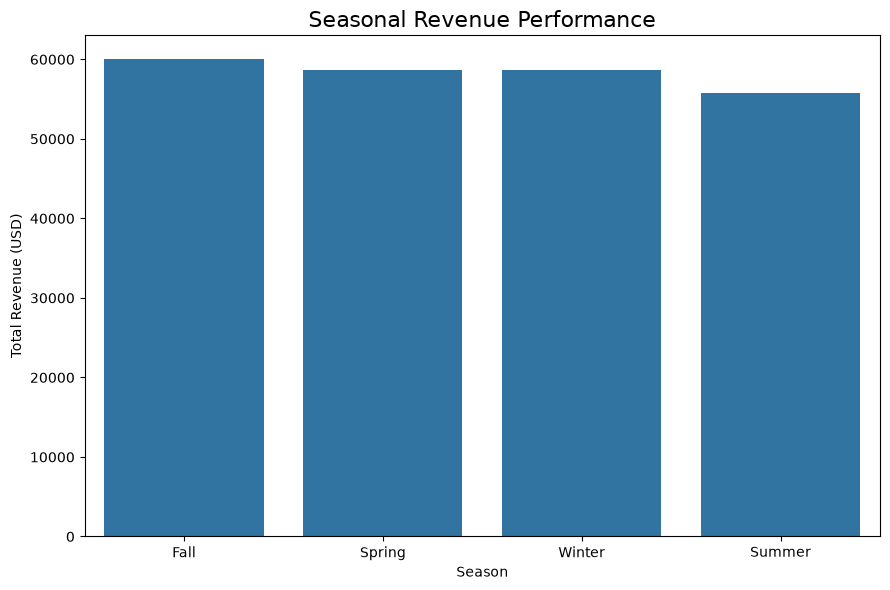

In [19]:
plt.figure(figsize=(9, 6))

sns.barplot(
    data=season_analysis.reset_index(),
    x="season",
    y="total_revenue"
)

plt.title("Seasonal Revenue Performance", fontsize=16)
plt.xlabel("Season")
plt.ylabel("Total Revenue (USD)")

plt.tight_layout()
plt.show()

In [20]:
payment_analysis = (
    df_clean.groupby("payment_method")
    .agg(
        customer_records=("customer_id", "count"),
        total_revenue=("purchase_amount_usd", "sum"),
        average_spending=("purchase_amount_usd", "mean")
    )
    .sort_values(by="total_revenue", ascending=False)
)

print("Payment Method Analysis:")
display(payment_analysis.round(2))

Payment Method Analysis:


,customer_records,total_revenue,average_spending
payment_method,,,
Credit Card,671,40310,60.07
PayPal,677,40109,59.25
Cash,670,40002,59.70
Debit Card,636,38742,60.92
Venmo,634,37374,58.95
Bank Transfer,612,36544,59.71


In [21]:
shipping_analysis = (
    df_clean.groupby("shipping_type")
    .agg(
        customer_records=("customer_id", "count"),
        total_revenue=("purchase_amount_usd", "sum"),
        average_spending=("purchase_amount_usd", "mean")
    )
    .sort_values(by="customer_records", ascending=False)
)

print("Shipping Method Analysis:")
display(shipping_analysis.round(2))

Shipping Method Analysis:


,customer_records,total_revenue,average_spending
shipping_type,,,
Free Shipping,675,40777,60.41
Standard,654,38233,58.46
Store Pickup,650,38931,59.89
Next Day Air,648,37993,58.63
Express,646,39067,60.48
2-Day Shipping,627,38080,60.73


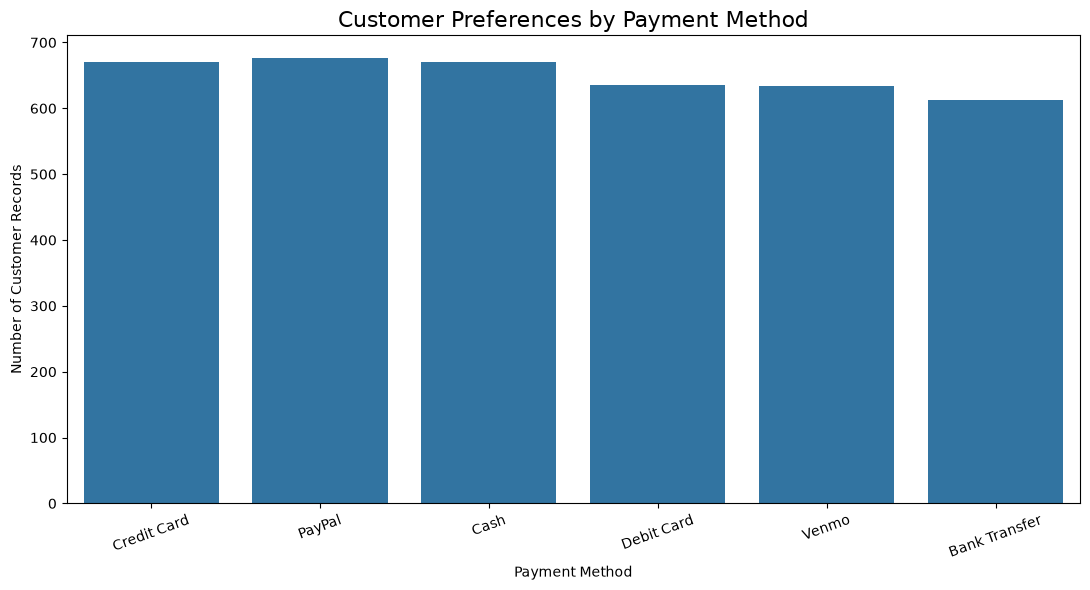

In [22]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=payment_analysis.reset_index(),
    x="payment_method",
    y="customer_records"
)

plt.title("Customer Preferences by Payment Method", fontsize=16)
plt.xlabel("Payment Method")
plt.ylabel("Number of Customer Records")
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

In [23]:
rating_analysis = (
    df_clean.groupby("category")
    .agg(
        average_rating=("review_rating", "mean"),
        total_reviews=("review_rating", "count")
    )
    .sort_values(by="average_rating", ascending=False)
)

print("Customer Satisfaction by Product Category:")
display(rating_analysis.round(2))

Customer Satisfaction by Product Category:


,average_rating,total_reviews
category,,
Footwear,3.79,599
Accessories,3.77,1240
Outerwear,3.75,324
Clothing,3.72,1737


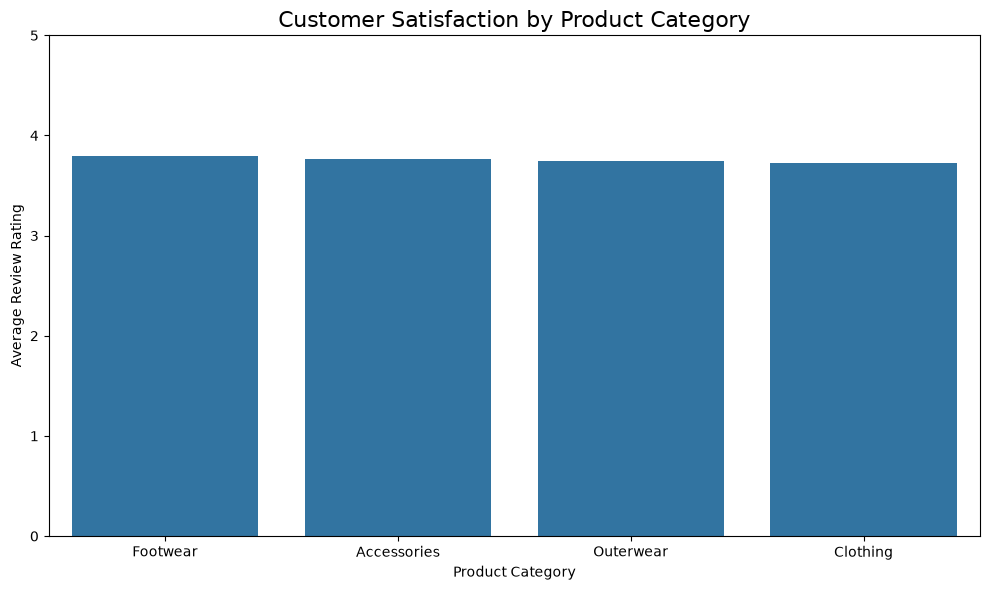

In [24]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=rating_analysis.reset_index(),
    x="category",
    y="average_rating"
)

plt.title("Customer Satisfaction by Product Category", fontsize=16)
plt.xlabel("Product Category")
plt.ylabel("Average Review Rating")
plt.ylim(0, 5)

plt.tight_layout()
plt.show()

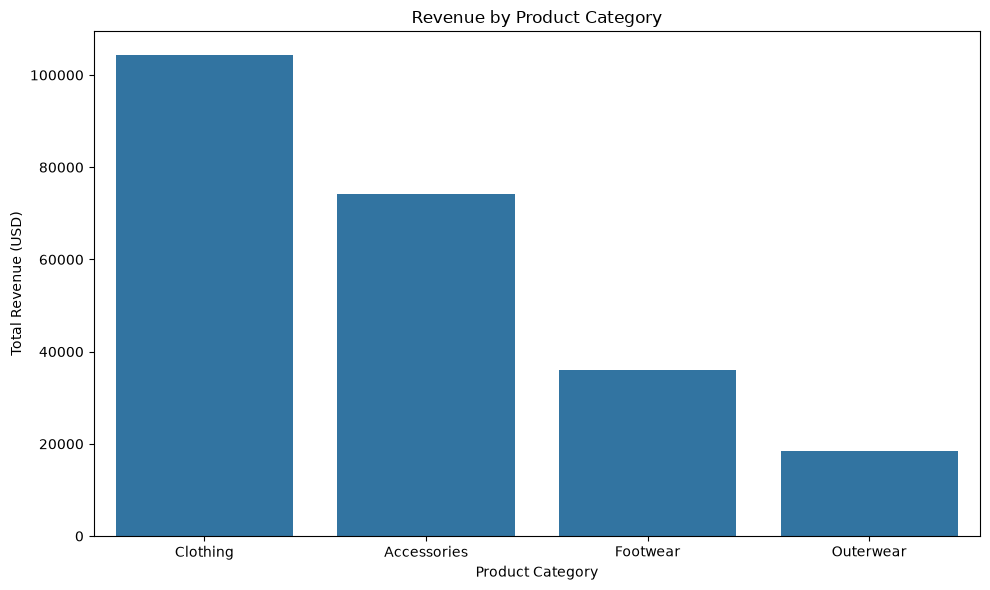

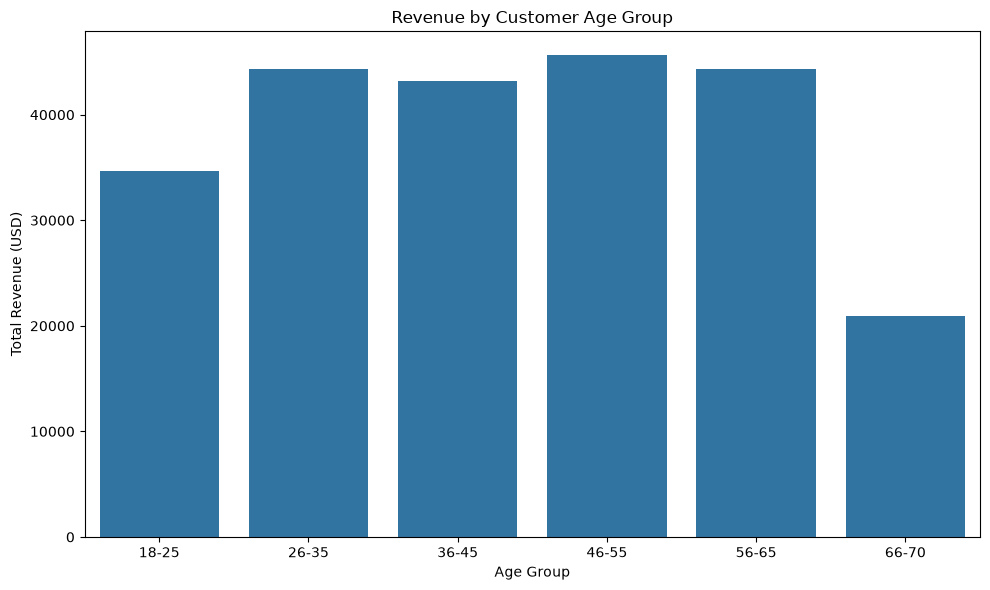

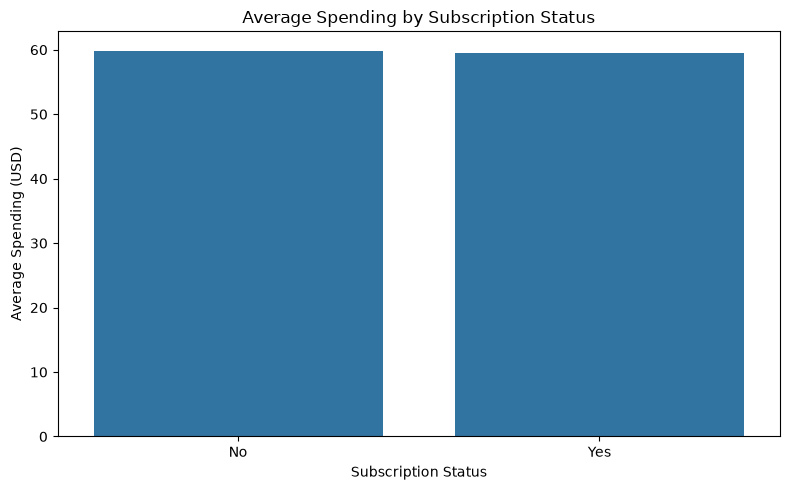

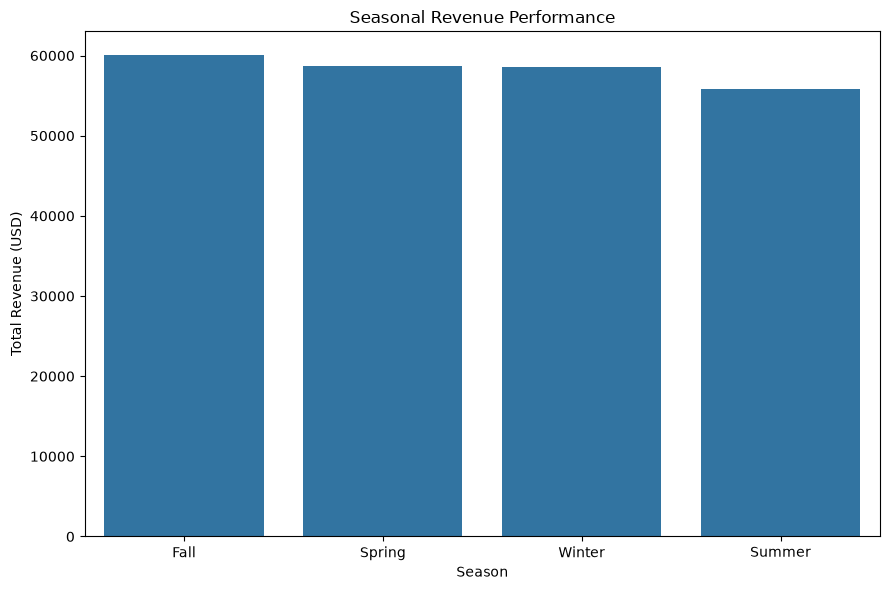

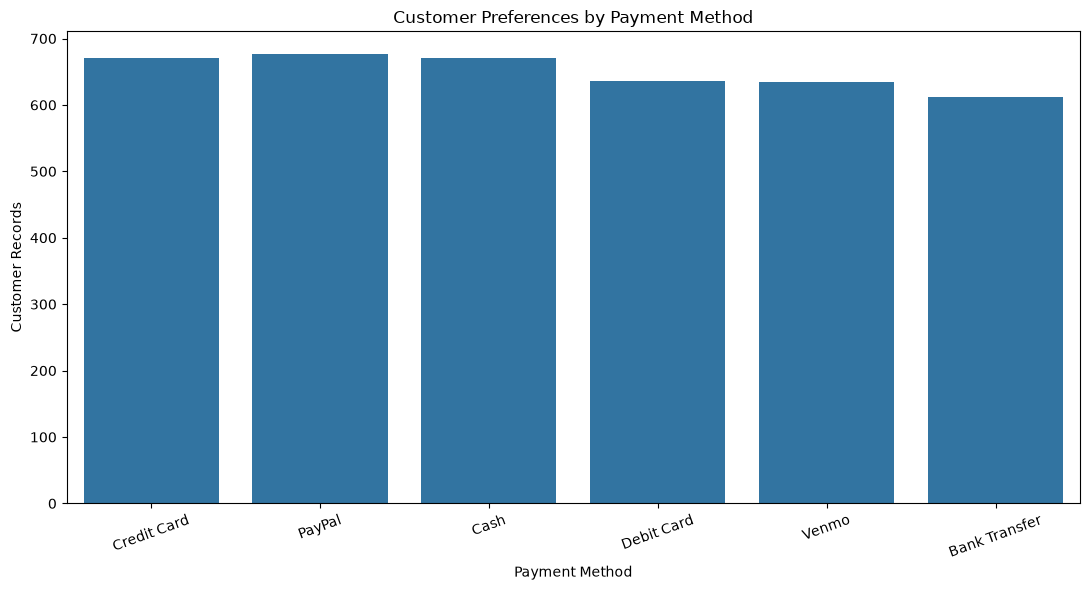

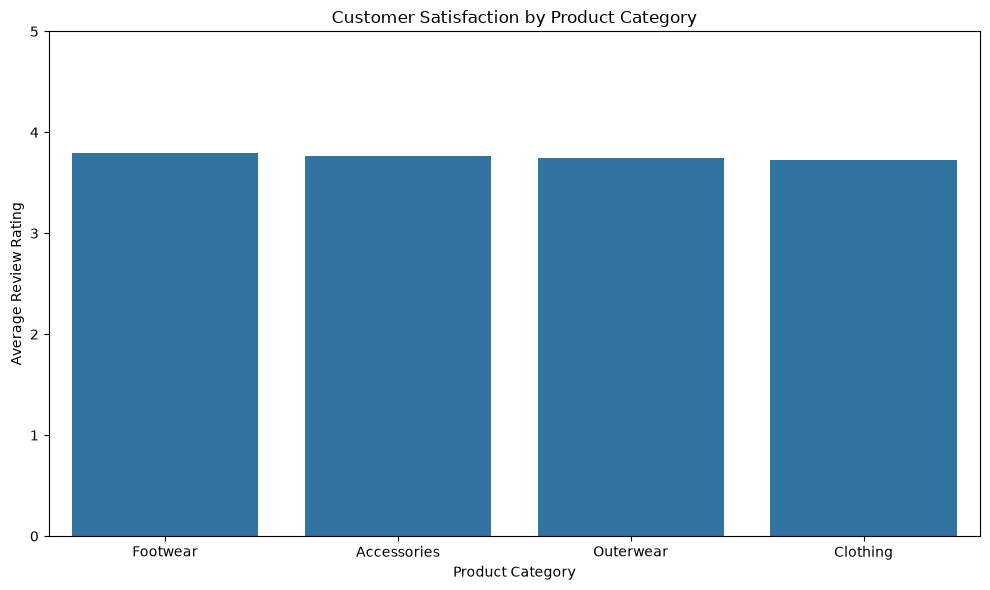

All six visualisations saved successfully!


In [25]:
import os

os.makedirs("Images", exist_ok=True)

# 1. Revenue by Product Category
plt.figure(figsize=(10, 6))
sns.barplot(data=category_analysis.reset_index(),
            x="category", y="total_revenue")
plt.title("Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue (USD)")
plt.tight_layout()
plt.savefig("Images/01_Revenue_by_Category.png", dpi=300)
plt.show()


# 2. Revenue by Customer Age Group
plt.figure(figsize=(10, 6))
sns.barplot(data=age_analysis.reset_index(),
            x="age_group", y="total_revenue")
plt.title("Revenue by Customer Age Group")
plt.xlabel("Age Group")
plt.ylabel("Total Revenue (USD)")
plt.tight_layout()
plt.savefig("Images/02_Revenue_by_Age_Group.png", dpi=300)
plt.show()


# 3. Average Spending by Subscription Status
plt.figure(figsize=(8, 5))
sns.barplot(data=subscription_analysis.reset_index(),
            x="subscription_status", y="average_spending")
plt.title("Average Spending by Subscription Status")
plt.xlabel("Subscription Status")
plt.ylabel("Average Spending (USD)")
plt.tight_layout()
plt.savefig("Images/03_Subscription_Analysis.png", dpi=300)
plt.show()


# 4. Seasonal Revenue Performance
plt.figure(figsize=(9, 6))
sns.barplot(data=season_analysis.reset_index(),
            x="season", y="total_revenue")
plt.title("Seasonal Revenue Performance")
plt.xlabel("Season")
plt.ylabel("Total Revenue (USD)")
plt.tight_layout()
plt.savefig("Images/04_Seasonal_Revenue.png", dpi=300)
plt.show()


# 5. Payment Method Preferences
plt.figure(figsize=(11, 6))
sns.barplot(data=payment_analysis.reset_index(),
            x="payment_method", y="customer_records")
plt.title("Customer Preferences by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Customer Records")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig("Images/05_Payment_Methods.png", dpi=300)
plt.show()


# 6. Customer Satisfaction by Category
plt.figure(figsize=(10, 6))
sns.barplot(data=rating_analysis.reset_index(),
            x="category", y="average_rating")
plt.title("Customer Satisfaction by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Average Review Rating")
plt.ylim(0, 5)
plt.tight_layout()
plt.savefig("Images/06_Customer_Satisfaction.png", dpi=300)
plt.show()

print("All six visualisations saved successfully!")

In [27]:
import os

os.makedirs("Data/Processed", exist_ok=True)

df_clean.to_csv(
    "Data/Processed/customer_shopping_cleaned.csv",
    index=False
)

print("Cleaned dataset exported successfully!")
print("Rows:", df_clean.shape[0])
print("Columns:", df_clean.shape[1])

Cleaned dataset exported successfully!
Rows: 3900
Columns: 19


In [28]:
readme_content = """# Customer Behaviour Analysis Using Python

## Project Overview
This project analyses customer shopping behaviour using Python.
The objective is to identify purchasing patterns, customer preferences,
sales trends, and customer satisfaction insights from a retail dataset.

## Dataset
- Source: Kaggle - Customer Shopping Trends Dataset
- Total Records: 3,900
- Original Columns: 18
- Currency: USD

## Tools and Technologies
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook

## Data Cleaning
- Inspected dataset structure and data types.
- Checked for missing values.
- Checked for duplicate records.
- Standardised column names.
- Created customer age groups.
- Exported the cleaned dataset.

## Business Questions
1. Which product category generates the highest revenue?
2. Which age group contributes the most revenue?
3. Do subscribed customers spend differently?
4. How do discounts and promotional codes relate?
5. Which season generates the highest revenue?
6. Which payment methods are most popular?
7. Which shipping methods do customers prefer?
8. Which product category receives the highest ratings?

## Key Findings
- Clothing generated the highest category revenue ($104,264).
- Customers aged 46-55 generated the highest age-group revenue ($45,619).
- Subscribed and non-subscribed customers had similar average spending.
- Discount Applied and Promo Code Used columns were identical.
- Fall generated the highest seasonal revenue ($60,018).
- PayPal was the most frequently used payment method.
- Free Shipping was the most popular shipping method.
- Footwear received the highest average customer rating (3.79/5).

## Visualisations
All project charts are available in the Images folder.

## Project Structure
- Data/Raw: Original dataset
- Data/Processed: Cleaned dataset
- Images: Analysis visualisations
- Reports: Project reports
- Customer_Behaviour_Analysis.ipynb: Python analysis notebook

## Conclusion
The analysis identifies important customer purchasing patterns,
category-level revenue trends, seasonal performance, and customer
satisfaction differences. These findings can help a retailer make
more informed business decisions.

## Disclaimer
This is an educational data analytics project using a publicly
available dataset. The revenue figures are in USD and represent
purchase amounts recorded in the dataset, not verified company revenue.
"""

with open("README.md", "w", encoding="utf-8") as file:
    file.write(readme_content)

print("README.md created successfully!")

README.md created successfully!


In [29]:
import os

print("Main project files and folders:")
print(os.listdir("."))

print("\nImages folder:")
print(os.listdir("Images"))

print("\nProcessed data folder:")
print(os.listdir("Data/Processed"))

Main project files and folders:
['.ipynb_checkpoints', 'Customer_Behaviour_Analysis.ipynb', 'Data', 'Images', 'README.md', 'Reports']

Images folder:
['01_Revenue_by_Category.png', '02_Revenue_by_Age_Group.png', '03_Subscription_Analysis.png', '04_Seasonal_Revenue.png', '05_Payment_Methods.png', '06_Customer_Satisfaction.png']

Processed data folder:
['customer_shopping_cleaned.csv']


In [30]:
with open(".gitignore", "w") as file:
    file.write(".ipynb_checkpoints/\n__pycache__/\n*.pyc\n")

print(".gitignore created successfully!")

.gitignore created successfully!


In [31]:
requirements = """pandas
numpy
matplotlib
seaborn
openpyxl
"""

with open("requirements.txt", "w") as file:
    file.write(requirements)

print("requirements.txt created successfully!")

requirements.txt created successfully!
